# ♟️ Chess Numba — 新舊引擎錦標賽對戰 (Colab Tournament Runner)

本 Notebook 用於在 Google Colab 雲端高並行 CPU 環境下，讓 **新版本引擎 (Candidate / New)** 與 **基準版本引擎 (Baseline / Old)** 進行成對換先（Color-swapped Pairs）錦標賽對抗：

### 🎯 本輪對抗設定 (實驗 A：修復 cutoff_cnt 殘留污染 + Fail-Low TT best_move 保護)
* **Engine 1 (New / Candidate)**: chess_engine/classical
  * ✅ **Stage 1 零樹變動加速與正交解耦（0-node delta）**：
    MovePicker 與 QSearch 的 SEE O(1) 快速短路與棋子型別重用、check_sq 位元棋盤重用、Step 14d 前置合法性檢查、Fail-Low 緩衝區邊界修復、Killer2 動態內插與歷史懲罰 Scale/Decay 完全解耦。
  * ✅ **實驗 A（修復 cutoff_cnt 殘留污染 + Fail-Low TT best_move 保護，對齊 SF19 Step 13 / TTEntry::save）**：
    1. **ProbCut cutoff_cnt[ply + 1] 隔離**：ProbCut 展開多吃子嘗試未截斷時，及時還原 search_context.cutoff_cnt[ply + 1]，防止其殘留 > 1 的高截斷計數污染主搜尋著法。
    2. **Grandchild cutoff_cnt[ply + 2] 歸零重置**：嚴格在 ProbCut 與 NMP 結束之後、進入主著法迴圈（while True:）之前執行 cutoff_cnt[ply + 2] = 0，防止殘留計數對主著法（如 tt_move）子節點內部產生高達 ~1.1 ply 的過度 LMR 削減懲罰。
    3. **Fail-Low TT best_move 微創保護**：在節點 Fail-Low（best_move == NO_MOVE）時，若原已有合法 tt_move 則保留 best_move = tt_move，僅在原本 tt_move == NO_MOVE 時才回退至 moves[0]（保持 IIR 穩定），徹底避免破壞轉置表中既有的高價值最佳步。
* **Engine 2 (Old / Baseline)**: chess_engine/classical_old（Stage 1 零樹變動基線）
* **時控模式**: 固定節點（400,000 nodes 長時控）
* **對戰規格**: 600 局（300 對開局交換白黑），64MB 轉置表，開局庫 data/openings.epd
* **統計模型**: SPRT（Sequential Probability Ratio Test）與 Elo 95% 置信區間


In [1]:
# =====================================================================
# 步驟 1: 檢視 Colab 雲端硬體規格與 CPU 核心數
# =====================================================================
!lscpu | grep "Model name\|Socket\|Thread\|NUMA\|CPU(s)"
!free -h
!python3 --version


CPU(s):                                  8
On-line CPU(s) list:                     0-7
Model name:                              AMD EPYC 7B12
Thread(s) per core:                      2
Socket(s):                               1
NUMA node(s):                            1
NUMA node0 CPU(s):                       0-7
               total        used        free      shared  buff/cache   available
Mem:            50Gi       1.4Gi        45Gi       2.2Mi       4.5Gi        49Gi
Swap:             0B          0B          0B
Python 3.13.16


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

In [2]:
# =====================================================================
# 步驟 2: 載入代碼庫與相依套件
# 支援方式 A：直接從 GitHub 倉庫拉取最新分支
# 支援方式 B：若您上傳了 zip 或放在 Google Drive，亦可解壓至 /content/chess_numba
# =====================================================================
import os

repo_url = "https://github.com/b08203031/chess_numba.git"
branch = "feat-initial-bitboard-setup"

if not os.path.exists('/content/chess_numba'):
    %cd /content
    !git clone -b {branch} {repo_url}

%cd /content/chess_numba
# 若代碼庫已存在，拉取最新變更
!git fetch origin {branch}
!git checkout -f {branch}
!git reset --hard origin/{branch}
!git clean -fd

# 安裝必要相依套件
!pip install -q numba chess numpy matplotlib scipy
print("\n🎉 環境與相依套件安裝完畢！")


/content/chess_numba
From https://github.com/b08203031/chess_numba
 * branch            feat-initial-bitboard-setup -> FETCH_HEAD
Already on 'feat-initial-bitboard-setup'
Your branch is up to date with 'origin/feat-initial-bitboard-setup'.
HEAD is now at cba7da1 feat(search): 實裝 Stage 1 零樹變動加速與正交解耦，並實作實驗 C（解耦 Correction History 的 static_score 與 corrected_eval）

🎉 環境與相依套件安裝完畢！


In [3]:
# =====================================================================
# 步驟 3: 嚴格核對新舊引擎代碼差異（驗證 Candidate vs Baseline）
# =====================================================================
import sys
from pathlib import Path

# 1) 清理 Python 模組記憶體快取
for m in list(sys.modules.keys()):
    if 'chess_engine' in m or 'tune_search' in m:
        del sys.modules[m]
!python -m tuner.sync_constants_snapshot
# 2) 顯示新舊版本差異（確認 classical vs classical_old 確實包含本次修改）
print("=" * 60)
print("🔍 新舊引擎邏輯代碼差異比對 (classical vs classical_old)：")
print("=" * 60)
!python tools/sync_classical_old.py --diff-code

# 3) 快速合約測試 (確保 JIT 與核心介面運作正常)
print("\n" + "=" * 60)
print("🔥 執行單元合約測試：")
print("=" * 60)
!python -m unittest tests/test_search_core_contracts.py


Unchanged tuner/constants_snapshot.py
🔍 新舊引擎邏輯代碼差異比對 (classical vs classical_old)：

[!] Differences found in search.py:
--- classical_old/search.py
+++ classical/search.py
@@ -1503,6 +1503,7 @@
 
     # --- H2: Static Evaluation & Improving Flag (computed BEFORE any pruning) ---
     static_score = -INFINITY
+    corrected_eval = -INFINITY
     improving = False
     
     # Correction History Adjustment
@@ -1518,6 +1519,7 @@
             raw_static_eval, _, _ = _evaluate_position_jit(piece_bbs, occupancy_bbs, game_state, True, search_context)
 
         static_score = apply_correction_history_score(game_state, search_context, raw_static_eval, ply)
+        corrected_eval = static_score
         
         # --- H2 Enhancement: Refine static_score using trusted TT Score Bounds ---
         if tt_hit and not is_exclusion_search:
@@ -3347,9 +3349,9 @@
                 is_capture = ((occupancy_bbs[enemy_side] & BB_SQUARES[to_sq]) != 0) or (move_flag == SPECIAL_MOVE_FLAG_EN_PASSANT)
       

In [4]:
# =====================================================================
# 步驟 4: 設定對戰參數並啟動錦標賽
# =====================================================================
import multiprocessing

# 自動偵測可用的 CPU 核心數 (留 1 核給主行程排程)
cpu_count = multiprocessing.cpu_count()
auto_concurrency = max(1, cpu_count - 1)

# --- 參數設定 ---
GAMES = 1000                 # 對局總數 (必須為偶數；400 局可獲穩健 Elo 95% CI)
NODES = 400000              # 每步節點預算 (300k 長時控；快速測試可改為 50000)
TT_MB = 64                  # 每個 Worker 的轉置表大小 (MB)
CONCURRENCY = auto_concurrency  # 平行對局數 (例如 7 或 11)

print("=" * 60)
print(f"♟️ 錦標賽參數配置：")
print(f"  總局數: {GAMES} 局 ({GAMES // 2} 對成對換先開局)" 
      f"  時控: {NODES:,} nodes/move" 
      f"  並行 Worker: {CONCURRENCY}" 
      f"  轉置表: {TT_MB} MB / context")
print("=" * 60)

%cd /content/chess_numba
!python tools/tournament.py --games {GAMES} --nodes {NODES} --concurrency {CONCURRENCY} --tt-mb {TT_MB} --seed 31415926


♟️ 錦標賽參數配置：
  總局數: 1000 局 (500 對成對換先開局)  時控: 400,000 nodes/move  並行 Worker: 7  轉置表: 64 MB / context
/content/chess_numba
Backend: inprocess; workers=7; TT=64 MB/context; openings=34700; seed=31415926
JIT plan: classical once + classical_old once; worker contexts share compiled code.
Warm-up: Kiwipete depth 14 for each Python/Numba backend, then one complete startpos game at depth 1 (all results discarded).
[pool] allocate worker 1/7
[warmup] New: Kiwipete depth=14...
info depth 1 score cp 1 nodes 494 nps 1126 hashfull 0.0% time 438 pv e2a6
info depth 2 score cp 1 nodes 885 nps 1825 hashfull 0.0% time 484 pv e2a6 b4c3
info depth 3 score cp -34 nodes 1872 nps 3850 hashfull 0.0% time 486 pv e2a6 b4c3 d2c3
info depth 4 score cp -34 nodes 2304 nps 4732 hashfull 0.0% time 486 pv e2a6 b4c3 d2c3 h3g2
info depth 5 score cp -125 nodes 5762 nps 11716 hashfull 0.0% time 491 pv e2a6 b4c3 d2c3 e6d5 e4d5
info depth 6 score cp -125 nodes 6352 nps 12886 hashfull 0.0% time 492 pv e2a6 b4c3 d2c3 e6d5 e4d

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

In [5]:
# =====================================================================
# 步驟 5: 產出統計報告與搜尋剪枝指標診斷
# =====================================================================
%cd /content/chess_numba
!python tournament_analysis/統計數據.py
!python tournament_analysis/parse_search_stats.py

report_path = Path("tournament_analysis/game_stats_report.txt")
if report_path.exists():
    print("\n" + "=" * 60)
    print("📊 對戰統計結果報告 (Game Stats Report)：")
    print("=" * 60)
    print(report_path.read_text(encoding='utf-8'))

search_report_path = Path("tournament_analysis/search_stats_report.txt")
if search_report_path.exists():
    print("\n" + "=" * 60)
    print("🔬 搜尋樹指標與剪枝診斷報告 (Search Stats Report)：")
    print("=" * 60)
    print(search_report_path.read_text(encoding='utf-8'))


/content/chess_numba
PGN: /content/chess_numba/tournament_analysis/tournament_results.pgn
Detected engines: ['New', 'Old']
Target: New
========== 引擎對戰深度分析報告 (New) ==========

來源 PGN: /content/chess_numba/tournament_analysis/tournament_results.pgn
序列順序: numeric Round order (PGN completion order reordered)
日期分佈: {'2026.10.20': 962}
White 名稱: Counter({'New': 481, 'Old': 481})
Black 名稱: Counter({'Old': 481, 'New': 481})

[1. 總體戰績與 Elo 表現]
總對局數 : 962 局
戰績統計 : 勝 189 | 和 558 | 負 215
勝率(含和) : 48.65%
和局率 : 58.00%
相對 Elo 變化 : -9.39
95% 信賴區間 : [-23.07, 4.25]
CI 單位 : color-swapped pair clustered (n=481 independent units)
  ⚖️ 尚無顯著差距（CI 含 0）


[2. 先手優勢與執色分析]
持白勝率 : 52.91% (勝:111 和:287 負:83)
持黑勝率 : 44.39% (勝:78 和:271 負:132)
賽局總體白方勝率 : 54.26%
卡方 p-value : 1.6758e-04


[3. 開局策略分析 (Top 5)]
【持白主流開局】
  - a3: n=19 勝率 47.37% (W1 D16 L2)
  - h3: n=19 勝率 63.16% (W8 D8 L3)
  - Nc3: n=18 勝率 47.22% (W2 D13 L3)
  - Be3: n=16 勝率 40.62% (W3 D7 L6)
  - cxd5: n=12 勝率 62.50% (W3 D9 L0)
【持黑面對的主流開局】
  - 面對 a3: n=17 勝率 


📈 累積分數曲線 (Cumulative Score)：


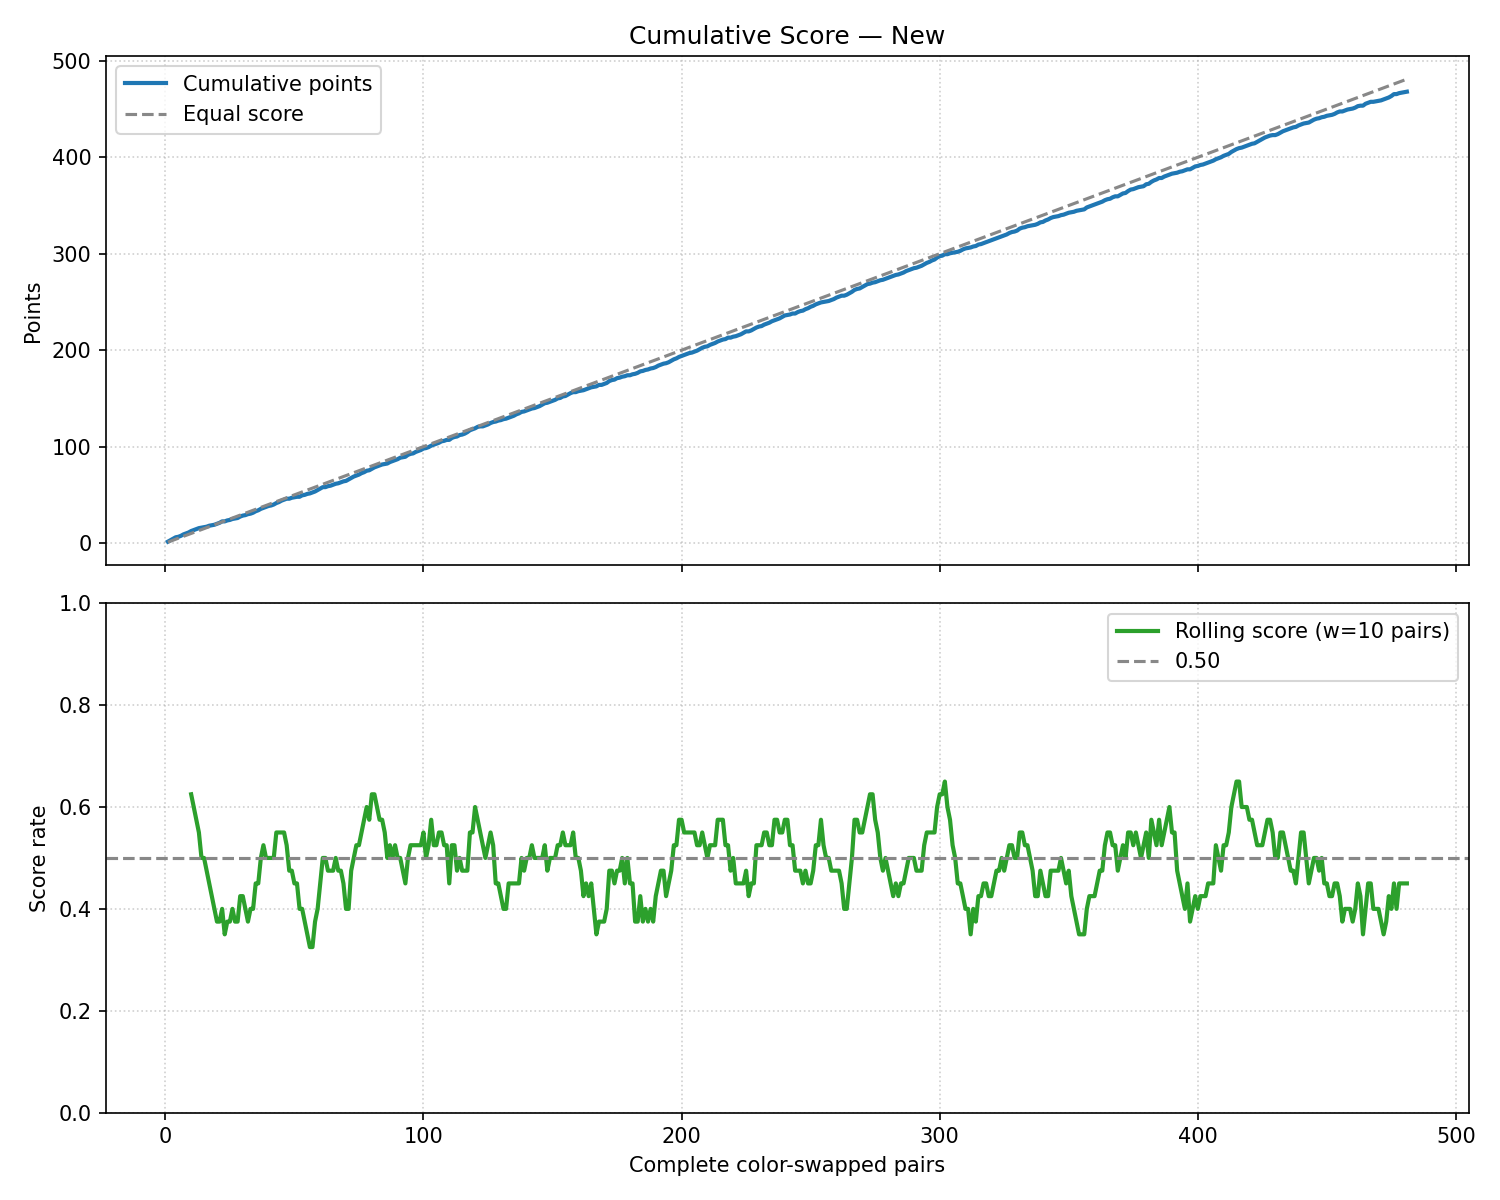


📈 Elo 置信區間收斂圖 (Elo CI)：


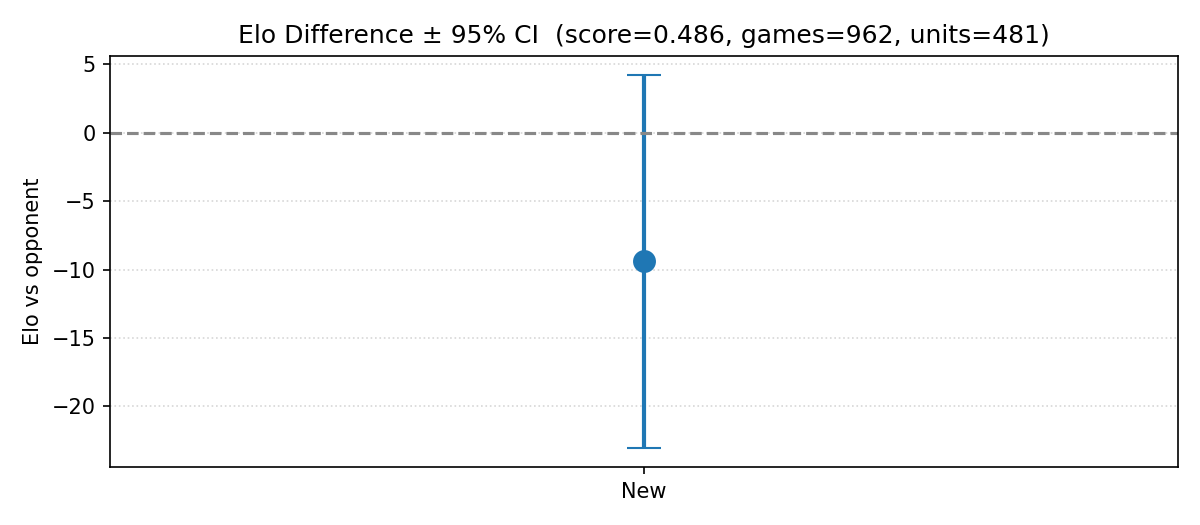


📈 每手搜尋深度 (Depth per Move)：


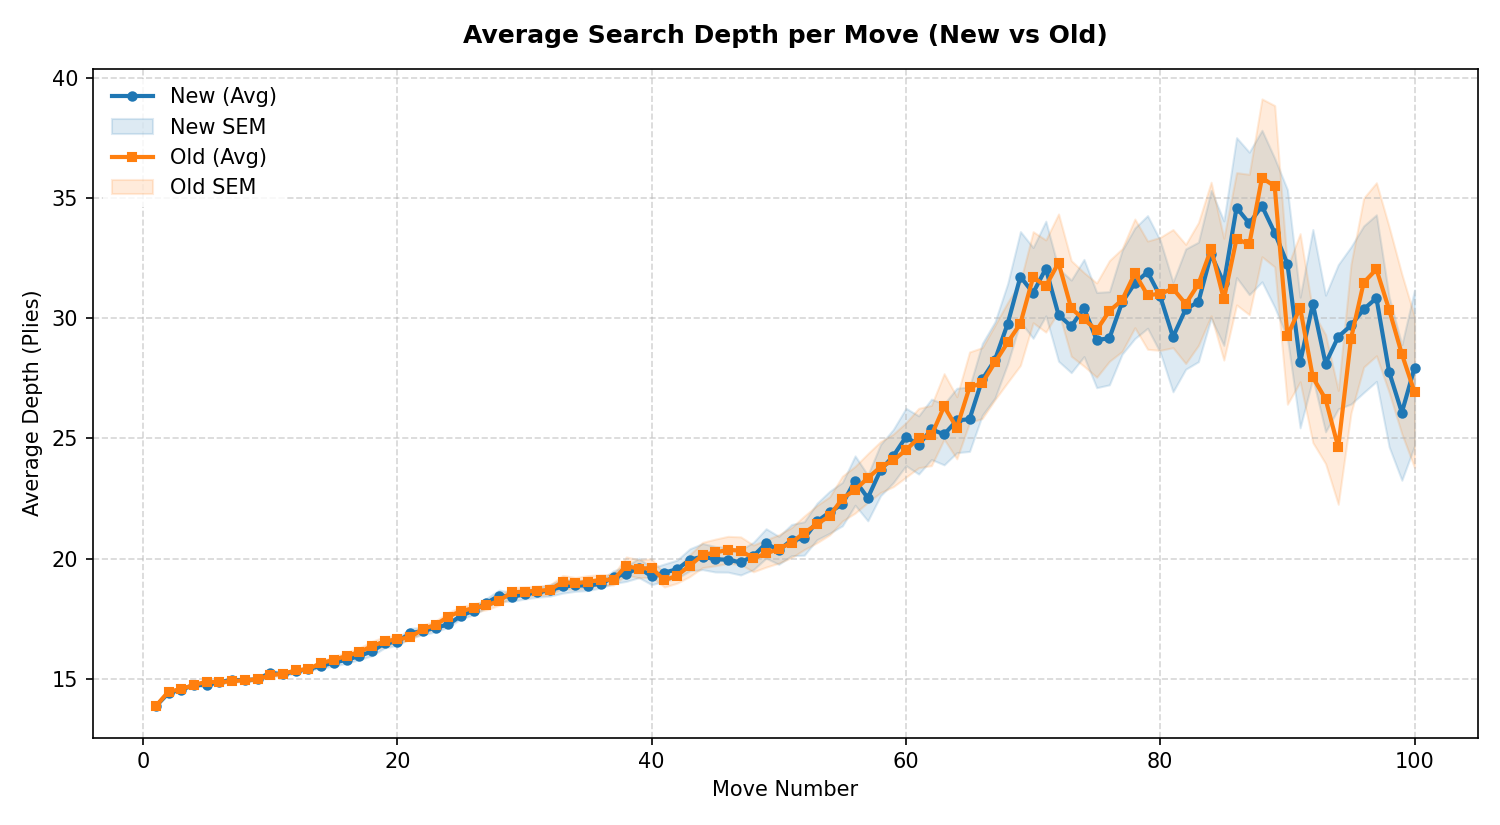


📈 同深度節點比例分佈 (Same-Depth Node Ratio)：


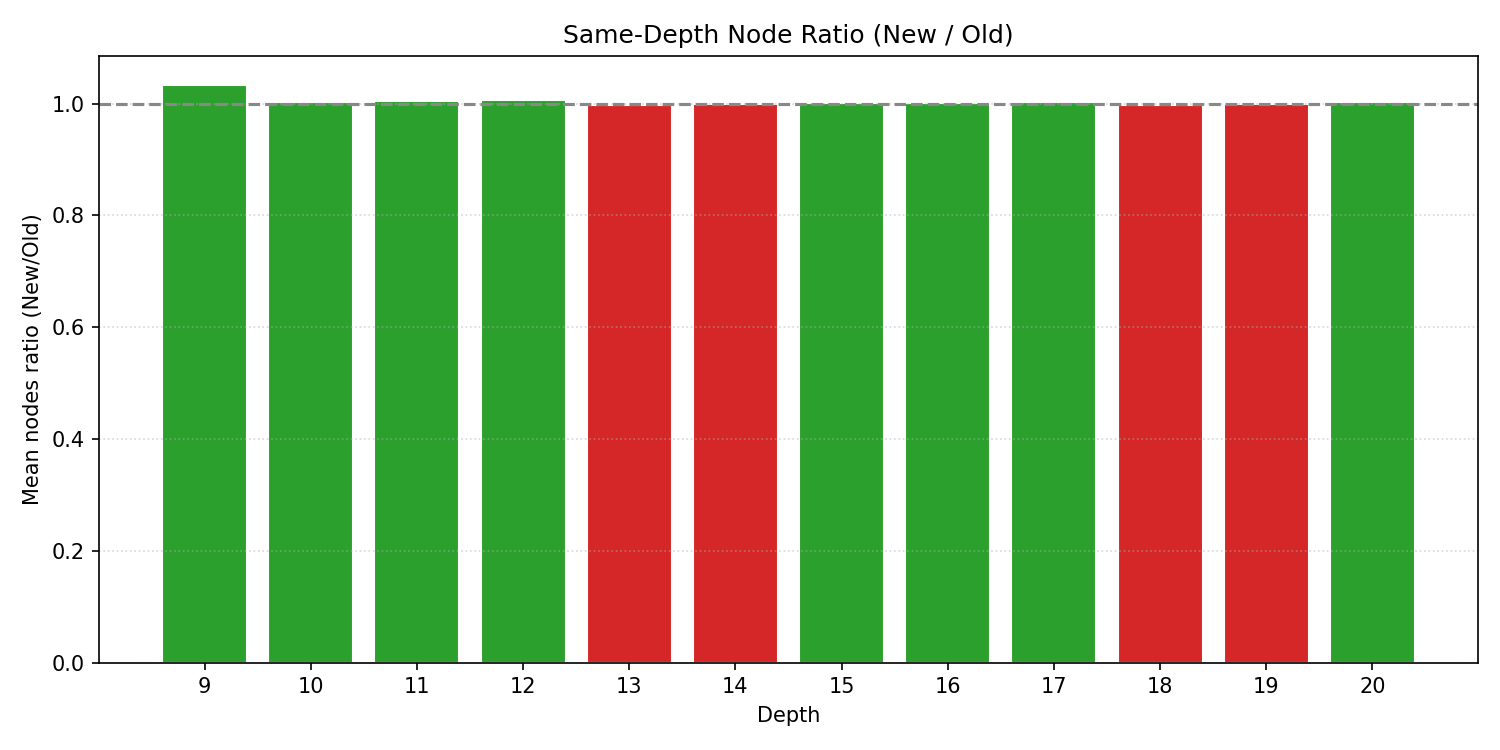


📈 平均節點數 vs 深度散佈 (Avg Nodes vs Depth)：


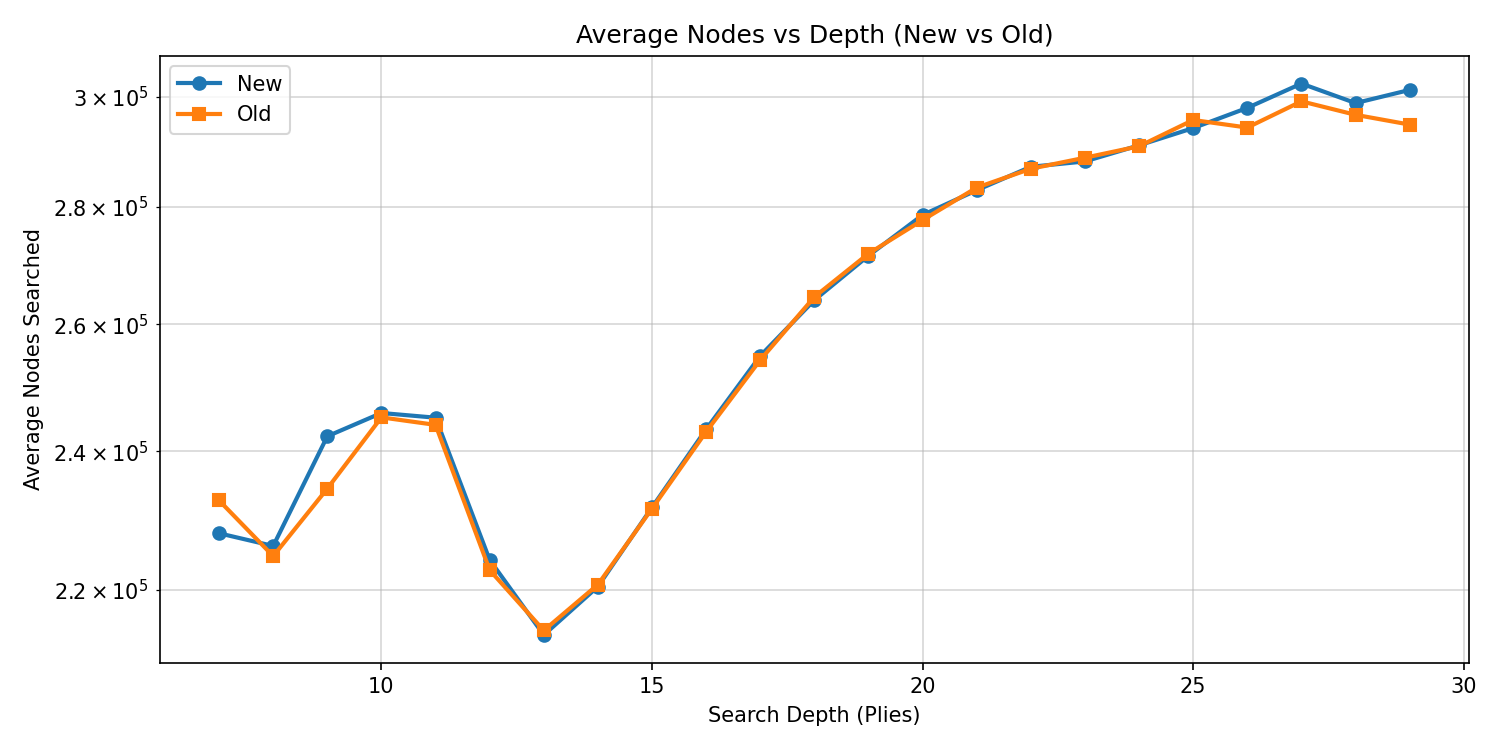


📈 黑白勝負分佈 (WDL by Color)：


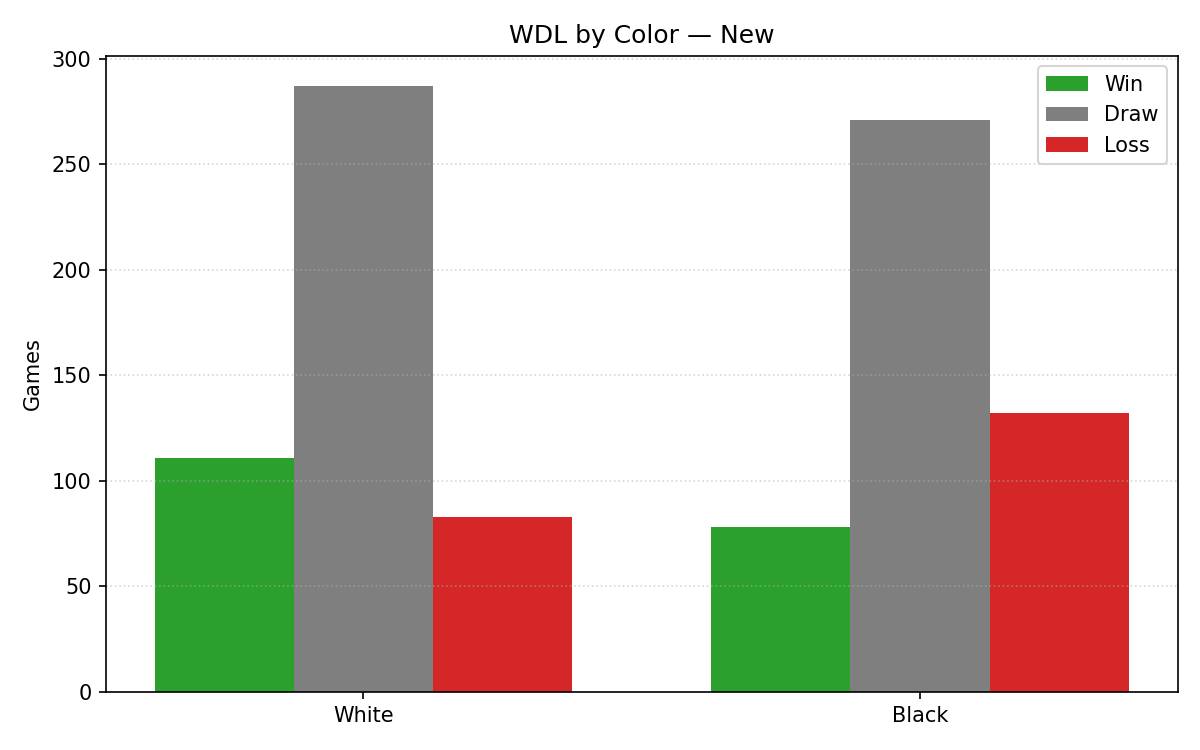

In [6]:
# =====================================================================
# 步驟 6: 視覺化關鍵圖表展示
# =====================================================================
import os
from IPython.display import Image, display

charts = [
    ("累積分數曲線 (Cumulative Score)", "tournament_analysis/cumulative_score.png"),
    ("Elo 置信區間收斂圖 (Elo CI)", "tournament_analysis/elo_ci.png"),
    ("每手搜尋深度 (Depth per Move)", "tournament_analysis/depth_per_move.png"),
    ("同深度節點比例分佈 (Same-Depth Node Ratio)", "tournament_analysis/same_depth_node_ratio.png"),
    ("平均節點數 vs 深度散佈 (Avg Nodes vs Depth)", "tournament_analysis/avg_nodes_vs_depth.png"),
    ("黑白勝負分佈 (WDL by Color)", "tournament_analysis/wdl_by_color.png"),
]

for title, path in charts:
    if os.path.exists(path):
        print(f"\n📈 {title}：")
        display(Image(filename=path))


In [7]:
# =====================================================================
# 步驟 7: 一鍵打包所有報告、圖表與 PGN 棋譜並下載
# =====================================================================
import datetime

timestamp = datetime.datetime.now().strftime("%Y%m%d_%H%M%S")
zip_filename = f"tournament_results_{timestamp}.zip"

!zip -q {zip_filename} tournament_analysis/*.png tournament_analysis/*.txt tournament_analysis/tournament_results.pgn
print(f"📦 已打包完成: {zip_filename}")

try:
    from google.colab import files
    files.download(zip_filename)
    print("⬇️ 已觸發下載！")
except ImportError:
    print(f"💡 本地環境執行，壓縮包位於當前目錄: {zip_filename}")


📦 已打包完成: tournament_results_20261020_205820.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

⬇️ 已觸發下載！


In [8]:
from google.colab import runtime

# 執行這行會直接中斷並釋放目前使用的虛擬機器運算資源
runtime.unassign()
